# Construindo uma mini-LLM com PyTorch: um Transformer do zero

Neste notebook didático, implementaremos um pequeno modelo de linguagem autoregressivo inspirado no GPT. Ele aprende a prever o próximo caractere e depois gera texto.

**Objetivos:** entender tokenização, embeddings de tokens e posições, atenção causal, multi-head attention, rede feed-forward, conexões residuais, LayerNorm, Cross Entropy, treinamento e geração autoregressiva.

> Este é um protótipo educacional, não uma LLM de uso geral. Usaremos um tokenizador por caractere e um corpus curto incluído no notebook para que o exercício funcione sem download de dados. LLMs reais normalmente usam subpalavras, muito mais dados, parâmetros e computação, além de etapas de ajuste e avaliação.

Instalação, se necessário: `pip install torch matplotlib`.

## 1. Bibliotecas e dispositivo

In [1]:
import random, time
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("PyTorch:", torch.__version__)
print("Dispositivo:", device)

PyTorch: 2.14.1+cpu
Dispositivo: cpu


## 2. Corpus de treinamento

O corpus curto abaixo contém textos em português sobre IA e modelos de linguagem. Um modelo de linguagem aprende a prever o próximo token a partir do contexto; não recebe categorias como “positivo” ou “negativo”.

Como o corpus é pequeno, a saída será limitada e poderá repetir trechos ou produzir sequências sem sentido.

In [2]:
corpus = '''
A inteligência artificial é uma área da computação que estuda sistemas capazes de realizar tarefas que normalmente exigem inteligência humana.
Um modelo de linguagem aprende padrões em sequências de texto. Durante o treinamento, observa um contexto e tenta prever o próximo token.
O processamento de linguagem natural permite que computadores analisem, representem e produzam linguagem humana.
Uma rede neural é formada por unidades matemáticas organizadas em camadas. Os parâmetros são ajustados durante o treinamento para reduzir o erro.
O Transformer utiliza mecanismos de atenção para combinar informações de diferentes posições de uma sequência.
Na atenção causal, cada posição pode consultar posições anteriores, mas não pode consultar os tokens futuros.
Embeddings transformam tokens discretos em vetores numéricos processados por uma rede neural.
Embeddings posicionais fornecem informação sobre a ordem dos tokens, pois a atenção sozinha não representa diretamente a posição.
A função de perda mede a diferença entre a distribuição prevista pelo modelo e o próximo token correto.
O gradiente indica como os parâmetros devem ser ajustados para diminuir a perda. O otimizador aplica essas atualizações.
Na geração autoregressiva, o modelo prevê um token, acrescenta esse token ao contexto e repete o processo.
Temperatura controla a distribuição de probabilidades usada na amostragem. Uma temperatura baixa tende a produzir escolhas mais previsíveis.
Modelos grandes são treinados com muitos dados e recursos computacionais. Mesmo assim, podem errar, inventar informações ou refletir problemas presentes nos dados.
Aprender a construir um modelo pequeno ajuda a entender os mecanismos básicos, mas não reproduz a capacidade de uma grande LLM.
O objetivo deste experimento é estudar a arquitetura e o treinamento, e não criar um assistente confiável para responder perguntas gerais.
'''.strip()

print("Caracteres no corpus:", len(corpus))
print(corpus[:500])

Caracteres no corpus: 1888
A inteligência artificial é uma área da computação que estuda sistemas capazes de realizar tarefas que normalmente exigem inteligência humana.
Um modelo de linguagem aprende padrões em sequências de texto. Durante o treinamento, observa um contexto e tenta prever o próximo token.
O processamento de linguagem natural permite que computadores analisem, representem e produzam linguagem humana.
Uma rede neural é formada por unidades matemáticas organizadas em camadas. Os parâmetros são ajustados dur


## 3. Tokenização: texto para números

Para simplificar, cada caractere é um token. Modelos reais frequentemente usam subpalavras, como BPE. Criamos `stoi` (caractere para ID) e `itos` (ID para caractere).

In [3]:
chars = sorted(set(corpus))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}

def encode(text):
    # Este tokenizador didático aceita somente caracteres do corpus.
    return [stoi[ch] for ch in text]

def decode(ids):
    return "".join(itos[int(i)] for i in ids)

all_ids = torch.tensor(encode(corpus), dtype=torch.long)
print("Tamanho do vocabulário:", vocab_size)
print("Texto:", corpus[:70])
print("IDs:", encode(corpus[:20]))
print("Reconstrução:", decode(encode(corpus[:70])))

Tamanho do vocabulário: 46
Texto: A inteligência artificial é uma área da computação que estuda sistemas
IDs: [4, 1, 21, 26, 32, 17, 24, 21, 19, 42, 26, 15, 21, 13, 1, 13, 30, 32, 21, 18]
Reconstrução: A inteligência artificial é uma área da computação que estuda sistemas


## 4. Exemplos de treinamento: prever o próximo token

Se a entrada for `A B C`, os alvos serão `B C D`. Usaremos janelas de tamanho fixo e separaremos os dados em treino e validação. A validação acompanha a perda em trechos não usados para atualizar os pesos.

In [4]:
split_idx = int(0.9 * len(all_ids))
train_data, val_data = all_ids[:split_idx], all_ids[split_idx:]
block_size = 96
batch_size = 32

def get_batch(split):
    data = train_data if split == "train" else val_data
    if len(data) <= block_size + 1:
        raise ValueError("Aumente o corpus ou reduza block_size.")
    starts = torch.randint(len(data) - block_size - 1, (batch_size,))
    x = torch.stack([data[i:i + block_size] for i in starts])
    y = torch.stack([data[i + 1:i + block_size + 1] for i in starts])
    return x.to(device), y.to(device)

xb, yb = get_batch("train")
print("Entrada:", xb.shape, "Alvos:", yb.shape)
print("Entrada:", decode(xb[0][:70].tolist()))
print("Alvo:   ", decode(yb[0][:70].tolist()))

Entrada: torch.Size([32, 96]) Alvos: torch.Size([32, 96])
Entrada:  em camadas. Os parâmetros são ajustados durante o treinamento para re
Alvo:    em camadas. Os parâmetros são ajustados durante o treinamento para red


## 5. Hiperparâmetros

`n_embd` é a dimensão dos vetores, `n_head` o número de cabeças e `n_layer` a quantidade de blocos Transformer. `block_size` é o comprimento máximo do contexto. A dimensão precisa ser divisível pelo número de cabeças.

In [5]:
n_embd = 96
n_head = 4
n_layer = 3
dropout = 0.1
learning_rate = 3e-4
max_iters = 800       # CPU: experimente 300–800; GPU: aumente se desejar
eval_interval = 100
eval_batches = 8
assert n_embd % n_head == 0
print(f"dimensão={n_embd}, cabeças={n_head}, blocos={n_layer}, iterações={max_iters}")

dimensão=96, cabeças=4, blocos=3, iterações=800


## 6. Atenção causal e multi-head attention

Cada cabeça cria **Query (Q)**, **Key (K)** e **Value (V)**. As queries são comparadas com as keys para calcular pesos que combinam os values. A máscara causal bloqueia posições futuras, evitando que o modelo “veja a resposta” durante o treinamento.

Várias cabeças podem aprender relações diferentes em paralelo.

In [6]:
class Head(nn.Module):
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k, q = self.key(x), self.query(x)
        scores = q @ k.transpose(-2, -1) * (k.shape[-1] ** -0.5)
        scores = scores.masked_fill(self.tril[:T, :T] == 0, float("-inf"))
        weights = self.dropout(F.softmax(scores, dim=-1))
        return weights @ self.value(x)

class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(num_heads * head_size, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.dropout(self.proj(out))

## 7. Feed-forward, conexões residuais e LayerNorm

A rede feed-forward processa cada posição após a atenção. Conexões residuais somam a entrada à saída de uma subcamada; LayerNorm normaliza as ativações; dropout atua como regularização durante o treinamento.

In [7]:
class FeedForward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )
    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)
    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

## 8. Modelo de linguagem MiniGPT

O modelo soma embeddings de tokens e de posições, aplica blocos Transformer e projeta a representação final em logits para cada token do vocabulário. A Cross Entropy compara os logits com o próximo token correto.

In [8]:
class MiniGPT(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        if T > block_size:
            raise ValueError(f"Contexto excede block_size={block_size}")
        tok_emb = self.token_embedding_table(idx)
        pos = torch.arange(T, device=idx.device)
        x = tok_emb + self.position_embedding_table(pos)
        x = self.blocks(x)
        logits = self.lm_head(self.ln_f(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(B*T, -1), targets.reshape(B*T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / max(temperature, 1e-5)
            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, next_id), dim=1)
        return idx

model = MiniGPT().to(device)
print("Parâmetros treináveis:", f"{sum(p.numel() for p in model.parameters()):,}")
logits, loss = model(xb, yb)
print("Formato dos logits:", logits.shape)
print("Perda inicial:", round(loss.item(), 4))

Parâmetros treináveis: 352,942
Formato dos logits: torch.Size([32, 96, 46])
Perda inicial: 4.0636


## 9. Treinamento: Cross Entropy, backpropagation e AdamW

A cada iteração, o modelo prevê o próximo caractere, calcula a perda, calcula gradientes com `backward()` e atualiza os pesos com AdamW. A perda de validação é calculada sem atualizar os parâmetros.

In [9]:
@torch.no_grad()
def estimate_loss():
    model.eval()
    result = {}
    for split in ["train", "val"]:
        losses = []
        for _ in range(eval_batches):
            X, Y = get_batch(split)
            _, loss = model(X, Y)
            losses.append(loss.item())
        result[split] = sum(losses) / len(losses)
    model.train()
    return result

optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
steps, train_losses, val_losses = [], [], []
start = time.time()
model.train()

for step in range(max_iters):
    if step % eval_interval == 0 or step == max_iters - 1:
        metrics = estimate_loss()
        steps.append(step)
        train_losses.append(metrics["train"])
        val_losses.append(metrics["val"])
        print(f"Iteração {step:4d} | treino={metrics['train']:.3f} | validação={metrics['val']:.3f}")

    xb, yb = get_batch("train")
    _, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()

print(f"Tempo de treinamento: {time.time()-start:.1f} segundos")

Iteração    0 | treino=4.059 | validação=4.058
Iteração  100 | treino=2.382 | validação=2.536
Iteração  200 | treino=2.175 | validação=2.463
Iteração  300 | treino=2.065 | validação=2.498
Iteração  400 | treino=1.941 | validação=2.561
Iteração  500 | treino=1.812 | validação=2.599
Iteração  600 | treino=1.592 | validação=2.692
Iteração  700 | treino=1.359 | validação=2.817
Iteração  799 | treino=1.117 | validação=2.979
Tempo de treinamento: 123.6 segundos


## 10. Interpretando a perda

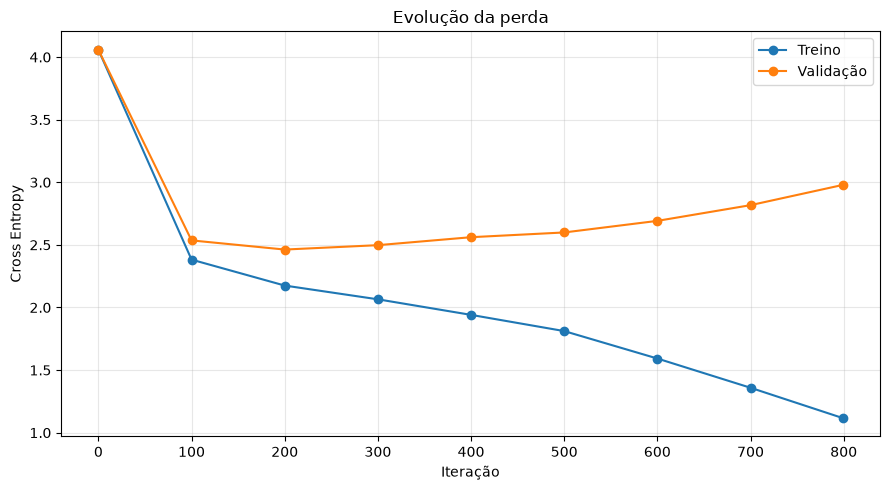

In [10]:
plt.figure(figsize=(9, 5))
plt.plot(steps, train_losses, marker="o", label="Treino")
plt.plot(steps, val_losses, marker="o", label="Validação")
plt.xlabel("Iteração")
plt.ylabel("Cross Entropy")
plt.title("Evolução da perda")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 11. Geração autoregressiva

A geração funciona em um ciclo: o modelo prevê o próximo token, sorteia um token conforme as probabilidades, adiciona-o ao contexto e repete. A temperatura altera a distribuição de amostragem: valores baixos tendem a ser mais previsíveis; valores altos, mais variados (mas não necessariamente melhores).

In [11]:
def gerar_texto(prompt, max_new_tokens=250, temperature=0.8):
    prompt_ids = encode(prompt)
    contexto = torch.tensor([prompt_ids], dtype=torch.long, device=device)
    saida = model.generate(contexto, max_new_tokens, temperature)
    return decode(saida[0].tolist())

prompt = "O modelo de linguagem"
print(gerar_texto(prompt, max_new_tokens=300, temperature=0.8))

O modelo de linguagem querante tem o natexte hurerente nte ve pa o to o tróxice o pento tarepro prvameróximo to to to, errrerrrocodos rntese petoken.
O deco a dinsão a cepontrroso.
O futr uirndenordtra anicocess des um rmade posirosisicos aretonailemos por odesicos por esumerenanto os r oceis a comona apomututonte tuto 


### Compare temperaturas

A amostragem é aleatória, então a saída pode mudar entre execuções.

In [12]:
for temp in [0.5, 0.8, 1.2]:
    print(f"\n--- Temperatura {temp} ---")
    print(gerar_texto("A inteligência artificial", max_new_tokens=160, temperature=temp))


--- Temperatura 0.5 ---
A inteligência artificialos porâmades trementros pororevinter pros imokengrans tos ados enacom po enader te pocos padur esisisina posisicar adama pos er atorororenar plizir es.
Emer cod

--- Temperatura 0.8 ---
A inteligência artificialem piza es ações mo de cases, usese prese tode m posinder posicarm todemarodes e us posor rosinumajunangumatuina naturemal o na e a o to turento proro.
O O troc

--- Temperatura 1.2 ---
A inteligência artificialeãokeç Dsbu foza denção a de poprevirvcos, som ustos sorpokenss, hacrenssonves, donsíatos cições utos dodoição a codeta fude e tompokêris o tjum, erentodeceta a


## 12. Mapa dos componentes

| Componente | Função |
|---|---|
| Corpus | Exemplos de texto para aprender padrões |
| Tokenizador | Converte texto em IDs |
| Embedding de tokens | Representação vetorial aprendida de cada token |
| Embedding posicional | Informa a ordem dos tokens |
| Atenção causal | Combina informação sem olhar o futuro |
| Multi-head attention | Aprende relações em paralelo |
| Feed-forward | Transforma representações por posição |
| Residual + LayerNorm | Apoiam o fluxo de informação e o treinamento |
| Cabeça de linguagem | Produz logits para o próximo token |
| Cross Entropy | Mede o erro de previsão |
| Backpropagation + AdamW | Calculam gradientes e atualizam parâmetros |
| Geração autoregressiva | Produz um token por vez |

## 13. Desafios para os alunos

1. Troque `n_head = 4` por `n_head = 2`. O modelo continua funcionando? Compare tempo e perda.
2. Troque `n_layer = 3` por `n_layer = 1`. O que muda?
3. Treine por menos e por mais iterações. A perda de validação sempre melhora?
4. Acrescente um parágrafo ao corpus e execute novamente as células desde a tokenização.
5. Explique por que a máscara causal é necessária.
6. Explique a diferença entre treinamento e geração.
7. Pesquise como BPE ou SentencePiece diferem da tokenização por caractere.

## 14. Limitações e próximos passos

Este exercício demonstra o fluxo central de um Transformer decoder-only, mas não equivale a uma LLM moderna. O corpus é pequeno, a tokenização é simples e o modelo não foi ajustado para seguir instruções. LLMs reais exigem grandes conjuntos de dados, escala computacional, avaliação sistemática e, em geral, etapas adicionais de ajuste e alinhamento.

Próximos passos: trocar o tokenizador por um de subpalavras, usar um corpus maior, comparar com um Transformer pré-treinado e estudar fine-tuning supervisionado.